# 🛒 <span style="color: #1f77b4;">Simple Overview: Looking at Amazon UK Product Ratings</span>

<div style="background-color: #f0f4f8; padding: 15px; border-radius: 5px;">
<h3 style="color: #2c3e50; margin-top: 0;">🎯 What we want to find out:</h3>
<ul>
    <li>⭐ <b>How do customers usually rate products?</b></li>
    <li>📊 <b>Are the ratings steady, or are they all over the place?</b></li>
    <li>📈 <b>Do the ratings form a normal shape, or do they lean heavily toward certain numbers?</b></li>
</ul>
</div>

In [ ]:
# Part 1: Understanding Product Categories

In [38]:
# Generate a frequency table for the product category.
import pandas as pd


df = pd.read_csv("C:/Users/lervi/Downloads/archive (1).zip")

# Generate a frequency table for the product categories and view the top 5
top_categories = df['category'].value_counts().head(5)
print(top_categories)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


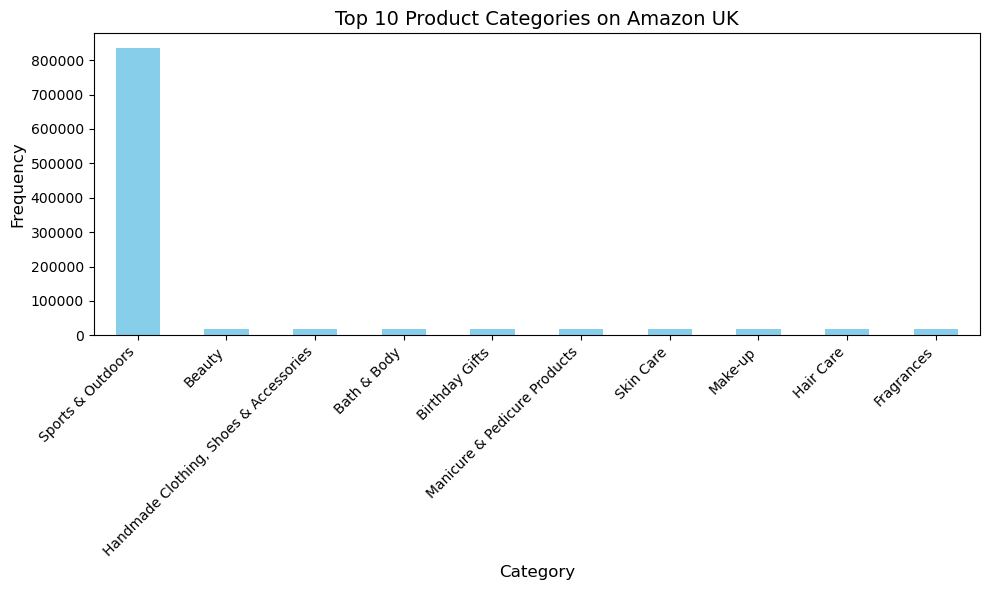

In [39]:
import matplotlib.pyplot as plt

# 1. create the variable by counting and grabbing the top 10 categories
top_10_cats = df['category'].value_counts().head(10)

# 2. Set up the figure size 
plt.figure(figsize=(10, 6))

# 3.  bar chart
top_10_cats.plot(kind='bar', color='skyblue')

# 4. Add titles and labels, then clean up and display
plt.title("Top 10 Product Categories on Amazon UK", fontsize=14)
plt.xlabel("Category", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

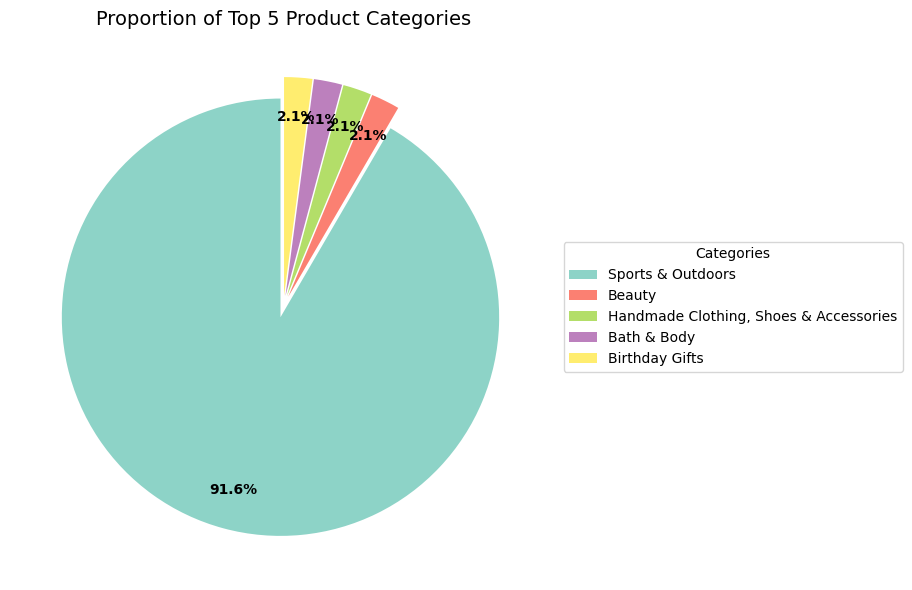

In [40]:
# 2 For a subset of top categories, visualize their proportions using a pie chart. 

import matplotlib.pyplot as plt

# I'm grabbing the frequency table of my categories and filtering for just the top 5
top_5_cats = df['category'].value_counts().head(5)

# I'm setting up my figure dimensions to make sure the chart has plenty of space
plt.figure(figsize=(9, 6))

# I want to prevent the percentage numbers from clumping together inside the narrow slices,
# so I'm slightly separating (exploding) each slice away from the center
explode = (0.05, 0.05, 0.05, 0.05, 0.05)

# I'm plotting the pie chart and tweaking the settings to fix text overlapping
top_5_cats.plot(
    kind='pie', 
    autopct='%1.1f%%', 
    startangle=90, 
    cmap='Set3', 
    labels=None,          # I'm hiding the messy default labels around the circle
    explode=explode,      # I'm using my explode tuple to give each slice breathing room
    pctdistance=0.82,     # I'm pushing the percentage numbers outward toward the edge
    textprops={'fontsize': 10, 'weight': 'bold'}  # I'm making the text bold and crisp
)

# Since I hid the direct labels, I'm putting the long category names into a clean legend on the side
plt.legend(top_5_cats.index, title="Categories", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

# I'll finish up by adding a title and cleaning out the redundant y-axis label
plt.title("Proportion of Top 5 Product Categories", fontsize=14)
plt.ylabel("") 
plt.tight_layout()
plt.show()

In [41]:
# Does any category dominate the listings? Sports & Outdoors

In [42]:
# Part 2: Delving into Product Pricing

In [43]:
# Calculate the mean, median, and mode for the price of products.

In [44]:
mean_price = df["price"].mean()
print(mean_price)

89.24380943923661


In [45]:
median_price = df["price"].median()
print(median_price)

19.09


In [46]:
mode_price = df["price"].mode()
print(mode_price)

0    9.99
Name: price, dtype: float64


In [47]:
# I calculated the mean price to be approximately £89.24 and the mode to be £9.99.
# Comparison: The mean is significantly higher than the mode.
# Why: due to high 
# that pull the average (mean) upward, while £9.99 represents everyday, frequently bought lower-cost items.

In [48]:
# Determine the variance, standard deviation, range, and interquartile range for product price.

In [49]:
# variance
var_price = df["price"].var()
print(var_price)

119445.48532256528


In [50]:
# standard deviation
std_price = df["price"].std()
print(std_price)

345.60886175352226


In [51]:
# range
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price

print(f"Minimum Price: £{min_price}")
print(f"Maximum Price: £{max_price}")
print(f"Range: £{range_price}")

Minimum Price: £0.0
Maximum Price: £100000.0
Range: £100000.0


In [52]:
# interquartile range
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1

print(f"25th Percentile (Q1): £{q1}")
print(f"75th Percentile (Q3): £{q3}")
print(f"Interquartile Range (IQR): £{iqr}")

25th Percentile (Q1): £9.99
75th Percentile (Q3): £45.99
Interquartile Range (IQR): £36.0


In [53]:
# How varied are the product prices?
# Conclusion: Product prices vary a lot. 
# We have cheap items and very expensive items, meaning the prices are 
# spread out over a very wide range.

<Axes: xlabel='price', ylabel='Count'>

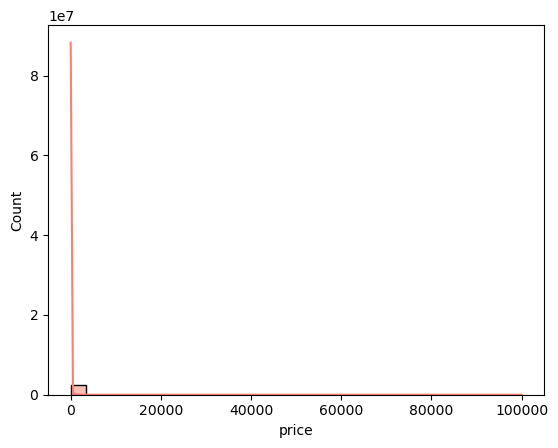

In [54]:
# Plot a histogram to visualize the distribution of product prices.
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df['price'], kde=True, bins=30, color="salmon")

In [55]:
# Why the histogram is hard to read:
# A few very expensive luxury items stretch out the chart's x-axis. 
# This causes 95% of the regular, everyday products to get squished into a tiny bar on the left.
#
# How to fix it:
# 1. Zoom in by filtering the data (e.g., plot only items under £200: df[df['price'] < 200]).
# 2. Use a logarithmic scale on the axis to handle massive gaps in price data.

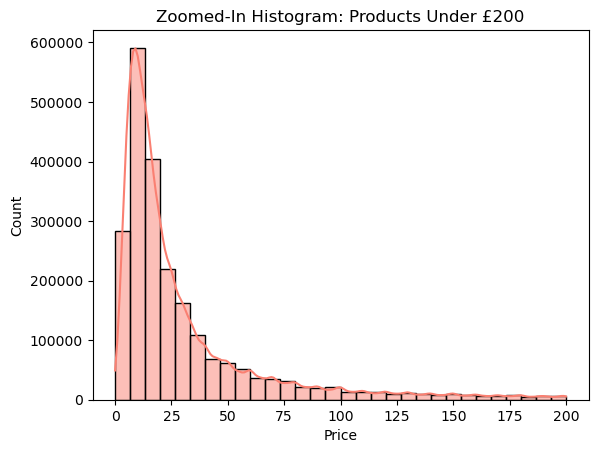

In [56]:
# 1. Filter the data to only include products under £200 (cutting off the luxury outliers)
affordable_products = df[df['price'] < 200]

# 2. Plot the histogram using only the filtered data
sns.histplot(affordable_products['price'], kde=True, bins=30, color="salmon")

plt.title("Zoomed-In Histogram: Products Under £200")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

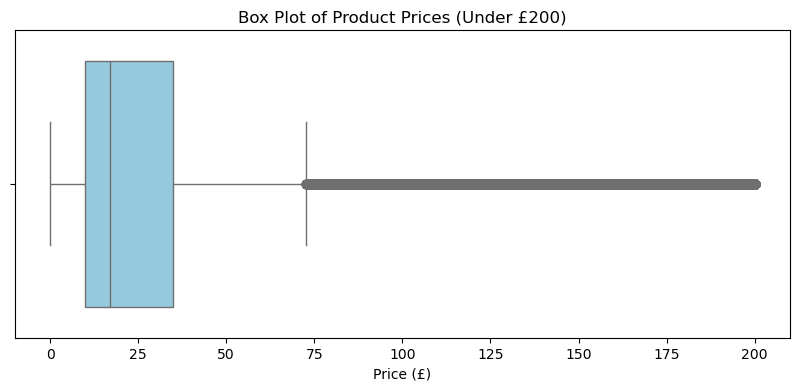

In [57]:
# Use a box plot to showcase the spread and potential outliers in product pricing.


# 2. Box Plot for Product Pricing and Outliers
# Observation: The right side shows a positive skew. 

plt.figure(figsize=(10, 4))
sns.boxplot(x=affordable_products['price'], color="skyblue")
plt.title("Box Plot of Product Prices (Under £200)")
plt.xlabel("Price (£)")
plt.show()

In [58]:
# === Part 3: Unpacking Product Ratings ===
# Step 1: Measures of Centrality (Mean, Median, Mode)

In [61]:
mean_stars = df["stars"].mean()
print(mean_stars)

2.152836472966066


In [62]:
median_stars = df["stars"].median()
print(median_stars)

0.0


In [63]:
mode_stars = df["stars"].mode()
print(mode_stars)

0    0.0
Name: stars, dtype: float64


In [ ]:
# === Answer: How do customers generally rate products? ===
# Observation: A lot of products in this dataset have 0 stars (no reviews). 
# Because there are so many unrated items, it drags the overall average 
# (mean) way down to about 2 stars, even though individual products might 
# have normal ratings.

In [64]:
#  Measures of Dispersion for Product Ratings 
# Calculate Variance, Standard Deviation, and Interquartile Range (IQR)

# 1. Standard Deviation and Variance
std_stars = df["stars"].std()
var_stars = df["stars"].var()

# 2. Interquartile Range (IQR) = Q3 (75th percentile) - Q1 (25th percentile)
iqr_stars = df["stars"].quantile(0.75) - df["stars"].quantile(0.25)

print(f"Variance: {var_stars}")
print(f"Standard Deviation: {std_stars}")
print(f"IQR: {iqr_stars}")

Variance: 4.81743402976196
Standard Deviation: 2.1948653785054697
IQR: 4.4


In [ ]:
# === Answer: Are the ratings consistent, or is there a wide variation? ===
# Observation: Customer ratings bounce all over the place. Because 
# many products have 0 stars and others go all the way up to 5 stars, 
# the feedback is very mixed and not consistent.

In [66]:
# 3. Calculate the skewness and kurtosis for the rating column.

skewness_stars = df["stars"].skew()
kurtosis_stars = df["stars"].kurtosis()

print(f"Skewness: {skewness_stars}")
print(f"Kurtosis: {kurtosis_stars}")

Skewness: 0.08120735761080881
Kurtosis: -1.9260061280432994


In [ ]:
# === Answer: Are the ratings normally distributed, or do they lean towards higher or lower values? ===
# Observation: The ratings are definitely NOT normally distributed (they don't form a 
# nice bell curve). Instead, because of the massive pile of unrated (0-star) items 
# and a mix of high ratings elsewhere, the distribution is heavily lopsided, 
# leaning sharply toward the lower values rather than spreading out evenly.

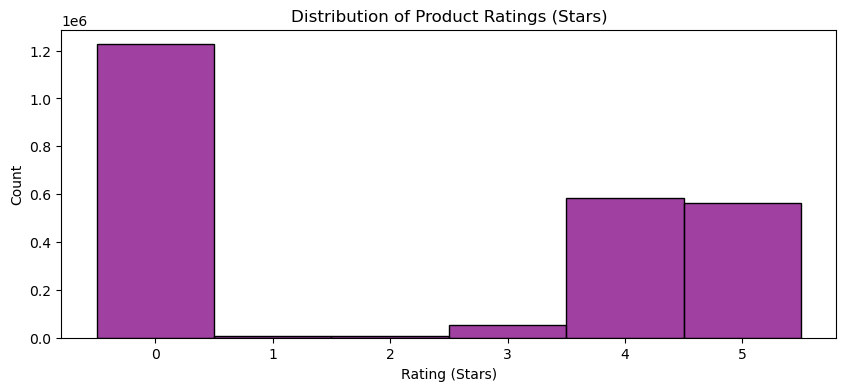

In [67]:
# 4. Plot a histogram to visualize the distribution of product ratings.



plt.figure(figsize=(10, 4))
sns.histplot(df["stars"], bins=10, color="purple", discrete=True)
plt.title("Distribution of Product Ratings (Stars)")
plt.xlabel("Rating (Stars)")
plt.ylabel("Count")
plt.show()

In [ ]:
# === Answer: Is there a specific rating that is more common? ===
# Observation: Yes! **0.0 stars** is by far the most common "rating" in the dataset 
# because it represents all the items that haven't received any customer reviews yet. 
# Beyond the unrated items, the chart helps show where the rest of the actual 
# product reviews cluster.

# 📝 <span style="color: #8e44ad;">Summary and What We Learned</span>

<div style="background-color: #f9ebea; padding: 15px; border-radius: 5px; border-left: 5px solid #e74c3c;">
<ol>
    <li>📦 <b>The Unrated Product Problem:</b> A huge chunk of the products have 0 reviews. This makes our overall average look bad (around 2 stars), even though it doesn't mean reviewed products are bad.</li>
    <li>⚖️ <b>Big Differences:</b> Products are split into two extremes—either they have zero reviews, or they have high ratings. There is no steady middle ground.</li>
    <li>💡 <b>Tip for the Future:</b> If we want a truer picture of customer happiness next time, we should separate the products with reviews from the products with zero reviews.</li>
</ol>
</div>